<a href="https://colab.research.google.com/github/ibader85/PredictiveAnalytics/blob/main/23_Hierarchical_Clustering_Using_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

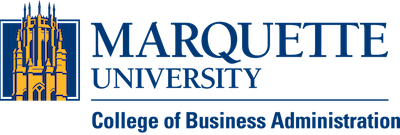

# BUAN 3065: Unlocking Business Insights with Predictive Analytics
# Hierarchical Clustering Using R

Instructor: Dr. Badar Al Lawati

**Disclaimer:** the content in this notebook is based on the content in Chapter 14 of Business Analytics by Sanjiv Jaggia, Alison Kelly, Kevin Lertwachara and Leida Chen. ISBN10: 126692602X | ISBN13: 9781266926020

Dataset relating to the crime rate (crimes
per 100,000 residents), the poverty rate (in %), and the median income (in $1,000s) for 41 cities in the United States

In [1]:
install.packages("readxl")
library(readxl)

myData <- read_excel("/content/Cities.xlsx")
myData

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



City,Crime,Poverty,Income
<chr>,<dbl>,<dbl>,<dbl>
Barnstable,710.6,3.8,58.422
Boston,1317.7,16.7,48.729
Brockton,1224.4,9.2,50.752
Cambridge,491.6,10.3,58.457
Fall River,1271.3,15.5,36.291
Fitchburg,866.8,14.8,43.828
Gloucester,156.1,5.5,58.568
Lawrence,815.0,27.9,31.718
Leominster,161.8,7.5,52.368


Install and load the caret, gains, pROC, and randomForest
packages

In [2]:
install.packages('cluster')
library(cluster)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [3]:
# exclude the City variable from the analysis; standardize the Crime, Poverty, and Income variables;
# and store their standardized values in a data frame called myData_std

myData_std <- scale(myData[ , 2:4])

We use the dist function to determine similarity among
observations, and store the distance matrix in a new variable
called d

Within the dist function, we use method to specify the
distance calculation

Options for the distance calculation include
“euclidean,” “manhattan,” “binary” (for Jaccard’s coefficient)

We specify “euclidean” to use the Euclidean
distance as the similarity measure

In [5]:
d <- dist(myData_std, method = "euclidean")

We use the agnes function to perform agglomerative clustering
and store the results in aResult

Within the agnes function, we use
*method* to specify the clustering method

Options for the
clustering method include “single” (single linkage), “complete”(complete linkage), “average,” “ward” (Ward’s method),
“weighted,” and “flexible.”

We specify **“ward”** to use the Ward’s
method.

The **diss** option (meaning dissimilarity) is set equal to
TRUE to indicate that variable d contains a distance matrix
instead of the original variables

In [7]:
# Enter “aResult” to obtain the clustering results including an agglomerative coefficient,
# which measures the strength of the clustering structure and whether or
# not there is a natural clustering structure in the data

aResult <- agnes(d, diss = TRUE, method = "ward")
aResult

Call:	 agnes(x = d, diss = TRUE, method = "ward") 
Agglomerative coefficient:  0.942097 
Order of objects:
 [1]  1 35 37  7 16 41 20 29  9 21 32  2  3  6 14 10 18  4 19 31 13 22 17 23 39
[26] 26 38 24 25 27 36 34  5 11 28 12 33 15  8 30 40
Height (summary):
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.1374  0.4094  0.7160  1.4408  1.5847 10.6120 

Available components:
[1] "order"  "height" "ac"     "merge"  "diss"   "call"   "method"

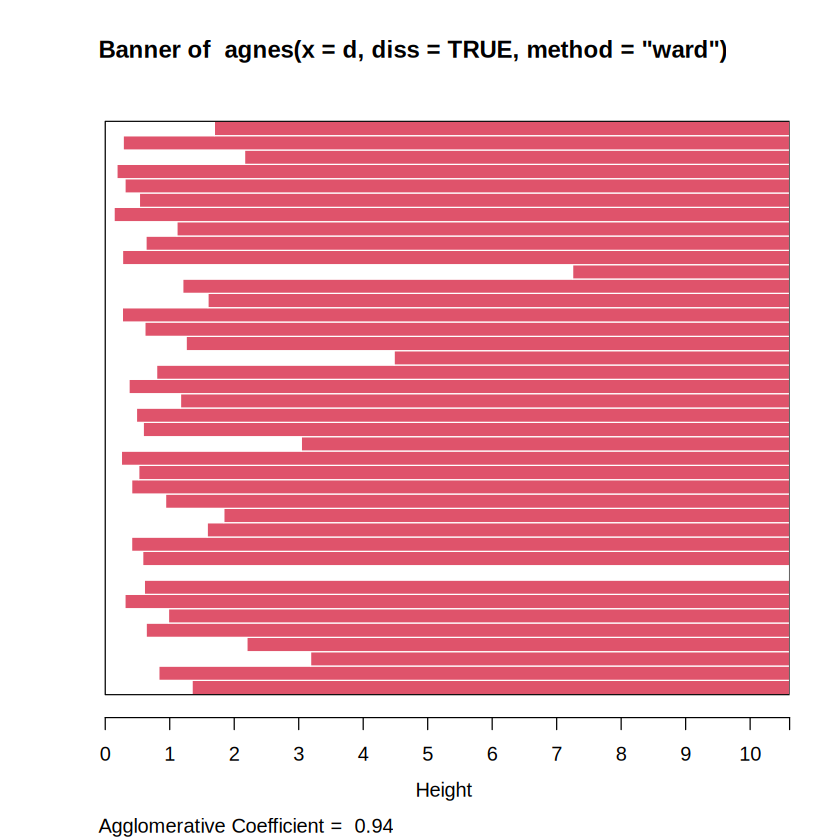

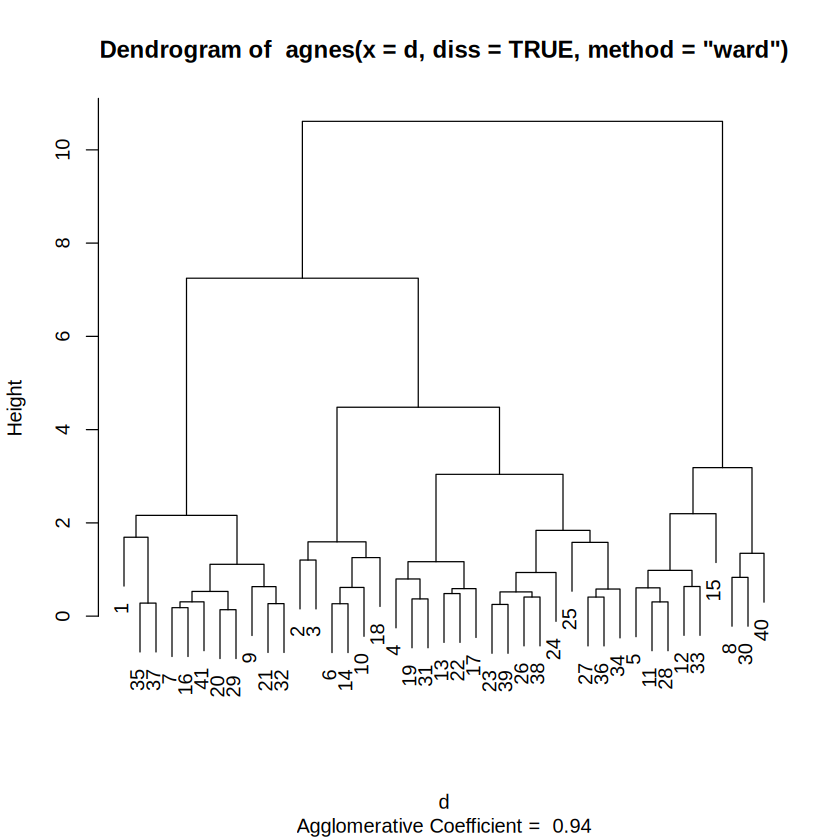

In [8]:
plot(aResult)

We use the cutree function
to create three distinct clusters and assign each observation to
one of the clusters.

The result is a vector of cluster numbers for
the observations. We save the result in a variable named
aClusters

In [9]:
aClusters <- cutree(aResult, k = 3)

In [10]:
# We can append the cluster membership to the original data
# frame, myData, using the data.frame function

myData <- data.frame(myData, aClusters)
View(myData)

City,Crime,Poverty,Income,aClusters
<chr>,<dbl>,<dbl>,<dbl>,<int>
Barnstable,710.6,3.8,58.422,1
Boston,1317.7,16.7,48.729,2
Brockton,1224.4,9.2,50.752,2
Cambridge,491.6,10.3,58.457,2
Fall River,1271.3,15.5,36.291,3
Fitchburg,866.8,14.8,43.828,2
Gloucester,156.1,5.5,58.568,1
Lawrence,815.0,27.9,31.718,3
Leominster,161.8,7.5,52.368,1


In [11]:
summary(subset(myData, aClusters==1))
summary(subset(myData, aClusters==2))
summary(subset(myData, aClusters==3))

        City        Crime          Poverty          Income        aClusters
 Length   :11   Min.   :124.8   Min.   :3.800   Min.   :52.37   Min.   :1  
 N.unique :11   1st Qu.:146.2   1st Qu.:4.300   1st Qu.:58.49   1st Qu.:1  
 N.blank  : 0   Median :161.8   Median :5.400   Median :59.73   Median :1  
 Min.nchar: 6   Mean   :235.9   Mean   :5.509   Mean   :61.39   Mean   :1  
 Max.nchar:10   3rd Qu.:241.5   3rd Qu.:6.500   3rd Qu.:63.16   3rd Qu.:1  
                Max.   :710.6   Max.   :7.900   Max.   :72.31   Max.   :1  

        City        Crime           Poverty          Income        aClusters
 Length   :21   Min.   :  72.0   Min.   : 5.90   Min.   :36.51   Min.   :2  
 N.unique :21   1st Qu.: 313.9   1st Qu.:10.30   1st Qu.:40.30   1st Qu.:2  
 N.blank  : 0   Median : 416.5   Median :12.70   Median :45.27   Median :2  
 Min.nchar: 6   Mean   : 544.2   Mean   :12.28   Mean   :45.64   Mean   :2  
 Max.nchar:11   3rd Qu.: 802.4   3rd Qu.:14.60   3rd Qu.:50.75   3rd Qu.:2  
                Max.   :1317.7   Max.   :16.70   Max.   :58.46   Max.   :2  

        City        Crime           Poverty          Income        aClusters
 Length   : 9   Min.   : 680.5   Min.   :15.50   Min.   :28.57   Min.   :3  
 N.unique : 9   1st Qu.:1075.9   1st Qu.:17.10   1st Qu.:32.32   1st Qu.:3  
 N.blank  : 0   Median :1152.8   Median :20.20   Median :35.26   Median :3  
 Min.nchar: 4   Mean   :1160.5   Mean   :21.46   Mean   :35.06   Mean   :3  
 Max.nchar:11   3rd Qu.:1271.3   3rd Qu.:24.20   3rd Qu.:36.29   3rd Qu.:3  
                Max.   :1775.0   Max.   :28.80   Max.   :40.93   Max.   :3  

To find the number of observations in each cluster, we use the
as.factor function to convert aCluster to categorical data and then
use the summary function to find the number of observations in
each cluster

In [12]:
summary(as.factor(aClusters))

1  2  3 
11 21  9